In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score
from sklearn.feature_extraction import text
from sklearn.decomposition import PCA
import nltk
nltk.download('wordnet')
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from collections import Counter

[nltk_data] Downloading package wordnet to /home/jack/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/jack/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


<h1>Bag of words vs Tfidf</h1>

Silhouette score for 3 clusters: 0.5108934036636599
Silhouette score for 5 clusters: 0.30816098070711023
Silhouette score for 7 clusters: 0.23306209315540116
Silhouette score for 9 clusters: 0.2027426167916368


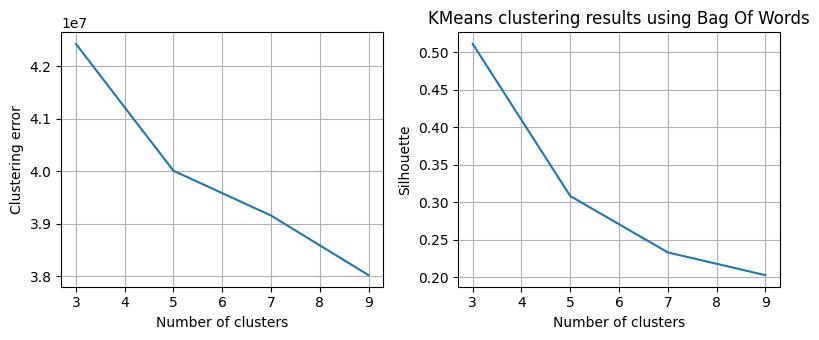

In [3]:
number_of_clusters=range(3, 10, 2)

kmeans_results = []
n_sample=100000
silhouetteScores = []

data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data
data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase
data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

vectorizer = CountVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(vectorizedData)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(vectorizedData, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.title("KMeans clustering results using Bag Of Words")
plt.tight_layout()
plt.show()

Silhouette score for 3 clusters: 0.0017913088083805402
Silhouette score for 5 clusters: 0.0019288774993500755
Silhouette score for 7 clusters: -0.001099245020226159
Silhouette score for 9 clusters: 0.00026781592171602964


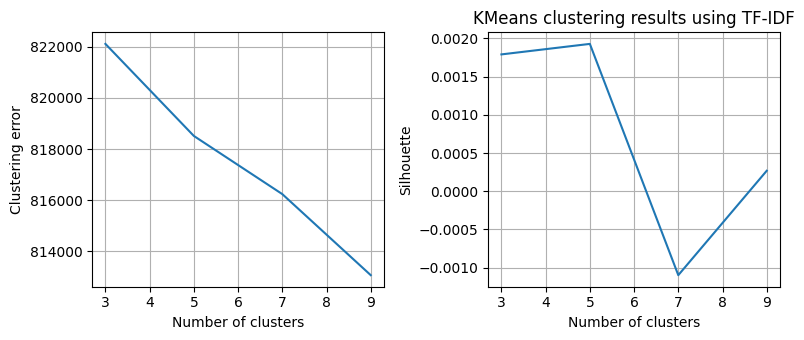

In [4]:
number_of_clusters=range(3, 10, 2)

kmeans_results = []
n_sample=100000
silhouetteScores = []

data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data
data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase
data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

vectorizer = TfidfVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(vectorizedData)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(vectorizedData, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.title("KMeans clustering results using TF-IDF")
plt.tight_layout()
plt.show()

Silhouette score for 3 clusters: 0.0017410638555009513
Silhouette score for 5 clusters: 0.0018817655196904906
Silhouette score for 7 clusters: -0.0009675706578112877
Silhouette score for 9 clusters: 0.0003549419305457966


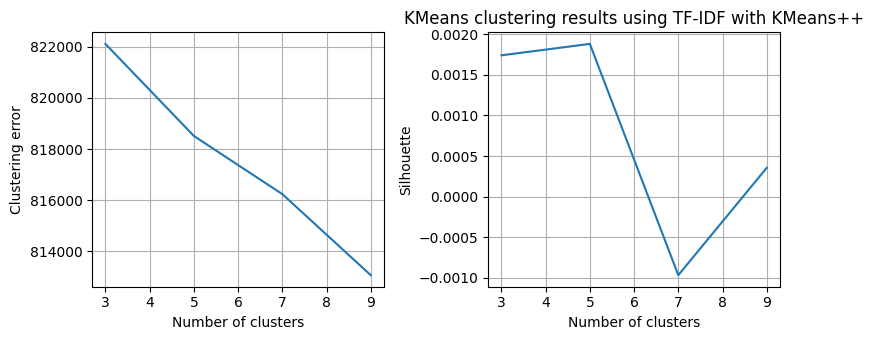

In [4]:
number_of_clusters=range(3, 10, 2)

kmeans_results = []
n_sample=100000
silhouetteScores = []

data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data
data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase
data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

vectorizer = TfidfVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

for n_clusters in number_of_clusters:
    kmeans = KMeans(
        init='k-means++',
        n_clusters=n_clusters,
        random_state=42)
    kmeans.fit(vectorizedData)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(vectorizedData, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.title("KMeans clustering results using TF-IDF with KMeans++")
plt.tight_layout()
plt.show()

Silhouette score for 3 clusters: 0.5130235825731474
Silhouette score for 5 clusters: 0.3080489731219354
Silhouette score for 7 clusters: 0.2306412256766898
Silhouette score for 9 clusters: 0.20360092886565334


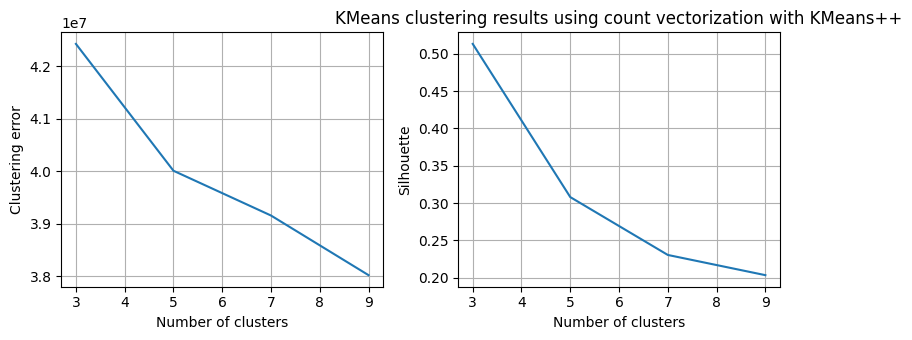

In [3]:
number_of_clusters=range(3, 10, 2)

kmeans_results = []
n_sample=100000
silhouetteScores = []

data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data
data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase
data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

vectorizer = CountVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

for n_clusters in number_of_clusters:
    kmeans = KMeans(
        init='k-means++',
        n_clusters=n_clusters,
        random_state=42)
    kmeans.fit(vectorizedData)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(vectorizedData, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.title("KMeans clustering results using count vectorization with KMeans++")
plt.tight_layout()
plt.show()

<h1>number of stopwords</h1>
Trying to see how the choiche of how many stopwords to remove impacts the clustering. We considered the most frequent words as stopwords.

Silhouette score for stopwords clusters: 0.24158261940922798
Silhouette score for stopwords clusters: 0.304624023003339
Silhouette score for stopwords clusters: 0.4186301534314733
Silhouette score for stopwords clusters: 0.3248445173959026
Silhouette score for stopwords clusters: 0.4149074746779137
Silhouette score for stopwords clusters: 0.30698181307589845
Silhouette score for stopwords clusters: 0.5141134833337347
Silhouette score for stopwords clusters: 0.4533875030669075
Silhouette score for stopwords clusters: 0.45290826966775916
Silhouette score for stopwords clusters: 0.32527739055437827


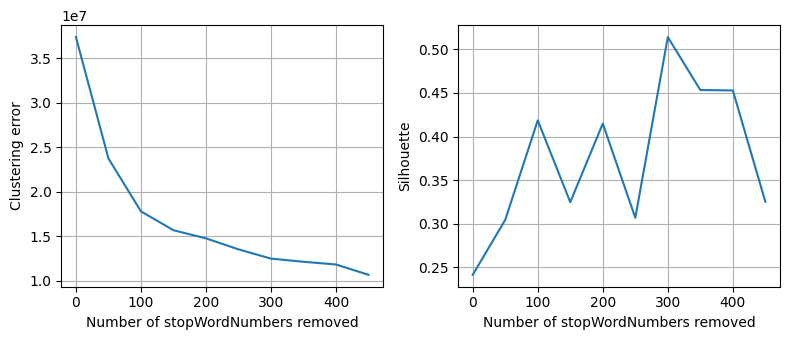

In [5]:
stopWordNumber = range(0, 500, 50)

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

kmeans_results = []
n_sample=100000
silhouetteScores = []

for i in stopWordNumber:
    data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data

    #remove every character that is not a letter or a number
    data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
    data['body'] = data['body'].str.lower() #convert to lowercase

    data = data.drop_duplicates()#drop duplicates
    data = data.dropna() #drop empty rows

    #lemmatize data
    lemmatizer = WordNetLemmatizer()
    data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))
    
    word_counts = data['body'].str.split().explode().value_counts()
    words_once = set(word_counts[word_counts == 1].index)
    most_freq_words = set(word_counts.nlargest(i).index)

    remove_words = words_once | most_freq_words

    data['body'] = data['body'].apply(remove_selected_words)

    data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
    data = data[~(data['body'] == '')] #drop empty comments
    vectorizer = CountVectorizer()
    vectorizedData = vectorizer.fit_transform(data['body'])
    n_clusters=7
    kmeans = KMeans(
        n_clusters, #will be choosen later
        #init='random', #centroids are initialized randomly TOO SLOW
        init='k-means++', #centroids are equally spaced -> probably better than random initialization. and should converge faster
        random_state=None, 
        n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
        max_iter=300
        )
    kmeans_results.append(kmeans.fit(vectorizedData))
        #print(f"Fitted KMeans with {k} clusters")#just to have a reference to how much time it's taking to execute
    try:
        silhouetteScores.append(silhouette_score(vectorizedData, kmeans_results[-1].labels_, sample_size=n_sample))
        print(f"Silhouette score for stopwords clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)
    
fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in stopWordNumber], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of stopWordNumbers removed")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in stopWordNumber], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of stopWordNumbers removed")
axs[1].set_ylabel("Silhouette")
axs[1].grid()

plt.tight_layout()
plt.show()

In [3]:
number_of_clusters=range(3, 10, 2)

kmeans_results = []
n_sample=100000
silhouetteScores = []

data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data
data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase
data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

vectorizer = CountVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

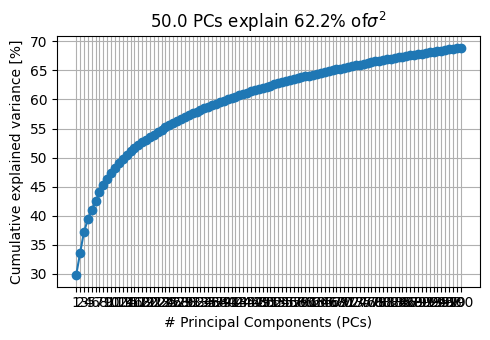

68.88485628209158


In [ ]:
PCA_number_components=100

pca=PCA(n_components=PCA_number_components)
pca.fit(vectorizedData)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
#plt.xticks([i for i in range(0,PCA_number_components,PCA_number_components//10)], [i for i in range(1,PCA_number_components+1,PCA_number_components//10)])
plt.grid()
plt.title(f'{(PCA_number_components/2)} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)-1], 2)}% of'+r'$\sigma^2$')
plt.tight_layout()
plt.show()
print(perc_cumul_exp_var[-1])

Silhouette score for 3 clusters: 0.5669371136912276
Silhouette score for 5 clusters: 0.3574032339152602
Silhouette score for 7 clusters: 0.28590908572112816
Silhouette score for 9 clusters: 0.22966264178210388


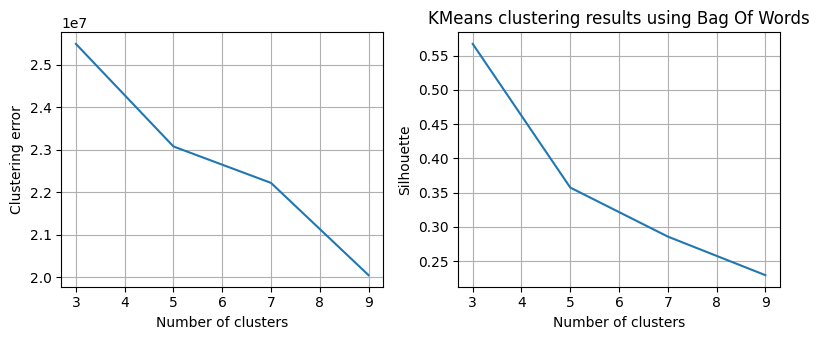

In [12]:
pca_result = pca.transform(vectorizedData)

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(pca_result)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(pca_result, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.title("KMeans clustering results using Bag Of Words")
plt.tight_layout()
plt.show()

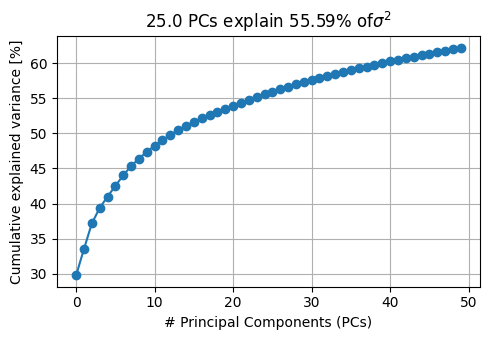

62.20193561033439


In [13]:
PCA_number_components=50

pca=PCA(n_components=PCA_number_components)
pca.fit(vectorizedData)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
#plt.xticks([i for i in range(0,PCA_number_components,PCA_number_components//10)], [i for i in range(1,PCA_number_components+1,PCA_number_components//10)])
plt.grid()
plt.title(f'{(PCA_number_components/2)} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)-1], 2)}% of'+r'$\sigma^2$')
plt.tight_layout()
plt.show()
print(perc_cumul_exp_var[-1])

Silhouette score for 3 clusters: 0.5855843407997737
Silhouette score for 5 clusters: 0.38343010781218434
Silhouette score for 7 clusters: 0.3064063182261103
Silhouette score for 9 clusters: 0.30408768495818916


ValueError: x and y must have same first dimension, but have shapes (4,) and (8,)

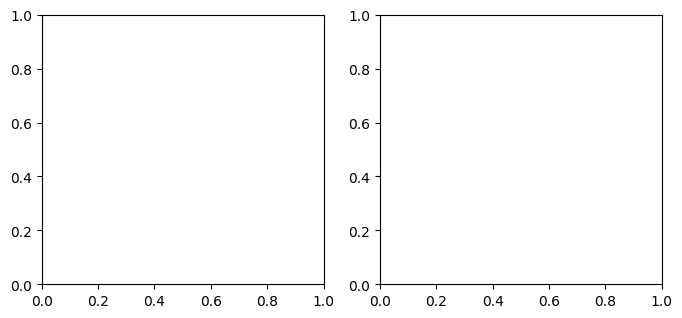

In [ ]:
pca_result = pca.transform(vectorizedData)

kmeans_results = []
silhouetteScores=[]

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(pca_result)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(pca_result, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.title("KMeans clustering results using Bag Of Words")
plt.tight_layout()
plt.show()

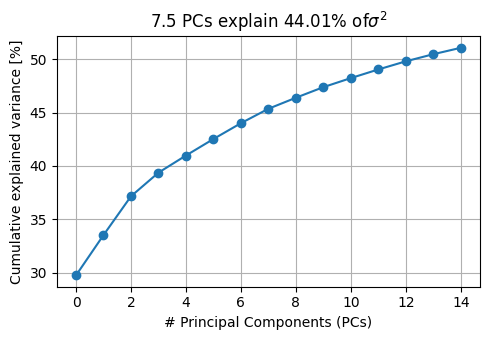

51.06613251440353


In [ ]:
PCA_number_components=15

pca=PCA(n_components=PCA_number_components)
pca.fit(vectorizedData)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
#plt.xticks([i for i in range(0,PCA_number_components,PCA_number_components//10)], [i for i in range(1,PCA_number_components+1,PCA_number_components//10)])
plt.grid()
#plt.title(f'{(PCA_number_components/2)} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)-1], 2)}% of'+r'$\sigma^2$')
plt.tight_layout()
plt.show()
print(perc_cumul_exp_var[-1])

Silhouette score for 3 clusters: 0.6282990367830248
Silhouette score for 5 clusters: 0.4329192759640145
Silhouette score for 7 clusters: 0.36216439566582254
Silhouette score for 9 clusters: 0.30626651184830417


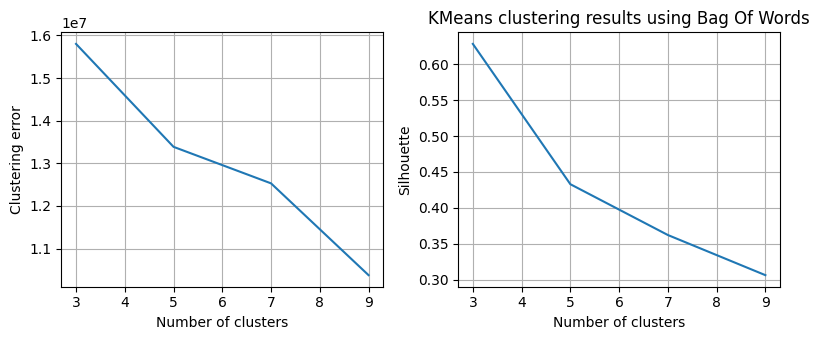

In [19]:
pca_result = pca.transform(vectorizedData)
kmeans_results = []
silhouetteScores=[]

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(pca_result)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(pca_result, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
#plt.title("KMeans clustering results using Bag Of Words")
plt.tight_layout()
plt.show()

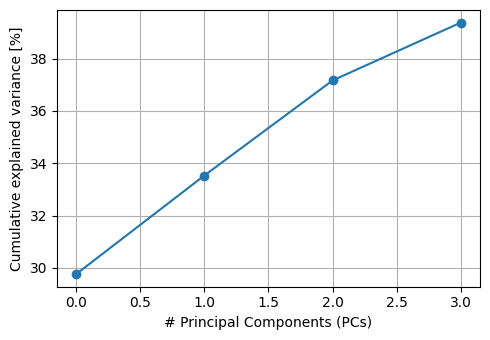

39.37514148837648


In [20]:
PCA_number_components=4

pca=PCA(n_components=PCA_number_components)
pca.fit(vectorizedData)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
#plt.xticks([i for i in range(0,PCA_number_components,PCA_number_components//10)], [i for i in range(1,PCA_number_components+1,PCA_number_components//10)])
plt.grid()
#plt.title(f'{(PCA_number_components/2)} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)-1], 2)}% of'+r'$\sigma^2$')
plt.tight_layout()
plt.show()
print(perc_cumul_exp_var[-1])

Silhouette score for 3 clusters: 0.7012209059821929
Silhouette score for 5 clusters: 0.6114611933894669
Silhouette score for 7 clusters: 0.4945515039773424
Silhouette score for 9 clusters: 0.45981483683883273


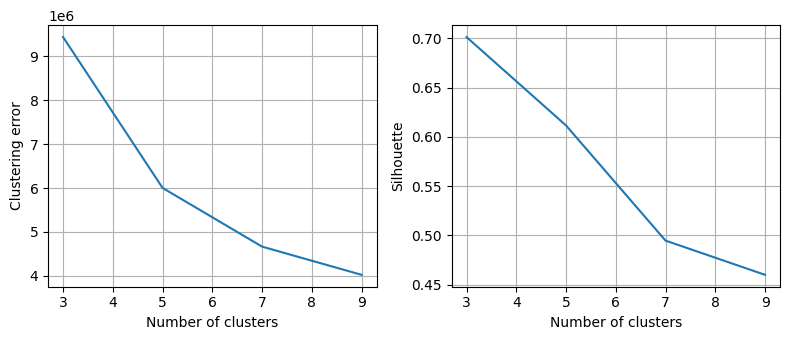

In [21]:
pca_result = pca.transform(vectorizedData)
kmeans_results = []
silhouetteScores=[]

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(pca_result)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(pca_result, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
#plt.title("KMeans clustering results using Bag Of Words")
plt.tight_layout()
plt.show()

In [ ]:
number_of_clusters=range(3, 10, 2)

kmeans_results = []
n_sample=100000
silhouetteScores = []

data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data
data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase
data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

vectorizer = TfidfVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

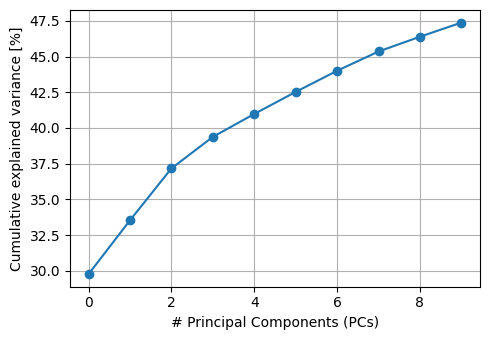

47.383058657001136


In [23]:
PCA_number_components=10

pca=PCA(n_components=PCA_number_components)
pca.fit(vectorizedData)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
#plt.xticks([i for i in range(0,PCA_number_components,PCA_number_components//10)], [i for i in range(1,PCA_number_components+1,PCA_number_components//10)])
plt.grid()
#plt.title(f'{(PCA_number_components/2)} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)-1], 2)}% of'+r'$\sigma^2$')
plt.tight_layout()
plt.show()
print(perc_cumul_exp_var[-1])

Silhouette score for 3 clusters: 0.6484655662214682
Silhouette score for 5 clusters: 0.4634792306158689
Silhouette score for 7 clusters: 0.3962318884426975
Silhouette score for 9 clusters: 0.3921884332344981


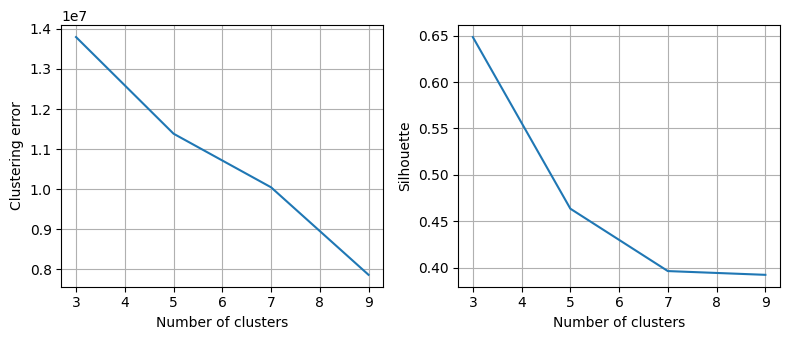

In [24]:
pca_result = pca.transform(vectorizedData)
kmeans_results = []
silhouetteScores=[]

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(pca_result)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(pca_result, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
#plt.title("KMeans clustering results using Bag Of Words")
plt.tight_layout()
plt.show()

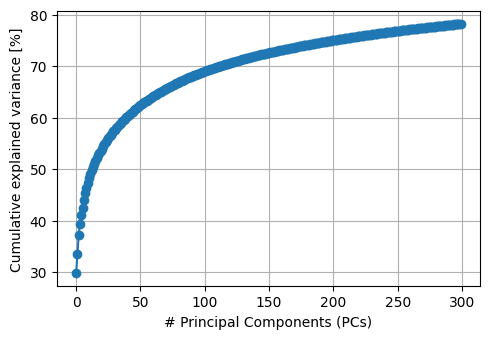

78.21191816740337
Silhouette score for 3 clusters: 0.5448421445127287
Silhouette score for 5 clusters: 0.33455337808376584
Silhouette score for 7 clusters: 0.27082964501085777
Silhouette score for 9 clusters: 0.26684948430684857


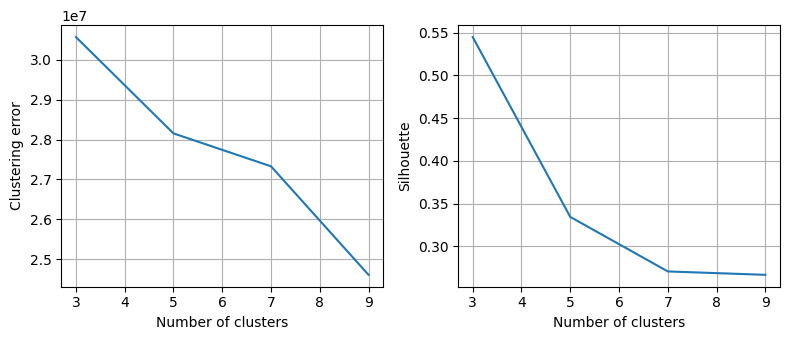

In [25]:
PCA_number_components=300

pca=PCA(n_components=PCA_number_components)
pca.fit(vectorizedData)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
#plt.xticks([i for i in range(0,PCA_number_components,PCA_number_components//10)], [i for i in range(1,PCA_number_components+1,PCA_number_components//10)])
plt.grid()
#plt.title(f'{(PCA_number_components/2)} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)-1], 2)}% of'+r'$\sigma^2$')
plt.tight_layout()
plt.show()
print(perc_cumul_exp_var[-1])
pca_result = pca.transform(vectorizedData)
kmeans_results = []
silhouetteScores=[]

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(pca_result)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(pca_result, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
#plt.title("KMeans clustering results using Bag Of Words")
plt.tight_layout()
plt.show()

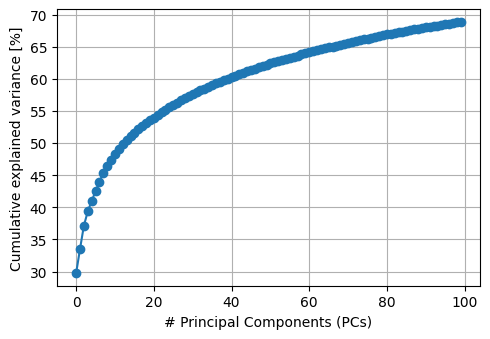

68.88485628209146
Silhouette score for 3 clusters: 0.5634392873280357
Silhouette score for 5 clusters: 0.35771096569403343
Silhouette score for 7 clusters: 0.2886743866636923
Silhouette score for 9 clusters: 0.22974980957993962


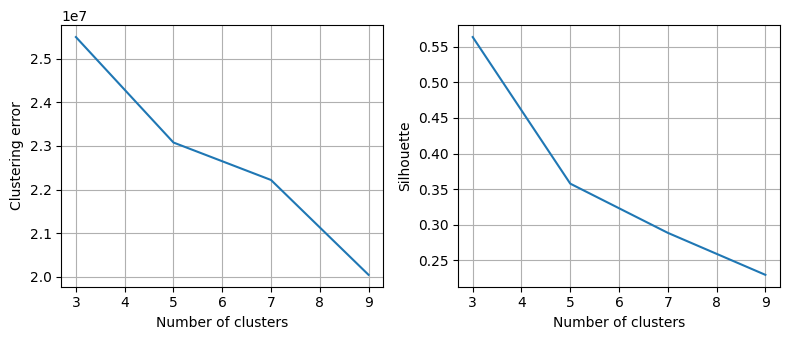

In [26]:
PCA_number_components=100

pca=PCA(n_components=PCA_number_components)
pca.fit(vectorizedData)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
#plt.xticks([i for i in range(0,PCA_number_components,PCA_number_components//10)], [i for i in range(1,PCA_number_components+1,PCA_number_components//10)])
plt.grid()
#plt.title(f'{(PCA_number_components/2)} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)-1], 2)}% of'+r'$\sigma^2$')
plt.tight_layout()
plt.show()
print(perc_cumul_exp_var[-1])
pca_result = pca.transform(vectorizedData)
kmeans_results = []
silhouetteScores=[]

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(pca_result)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(pca_result, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
#plt.title("KMeans clustering results using Bag Of Words")
plt.tight_layout()
plt.show()

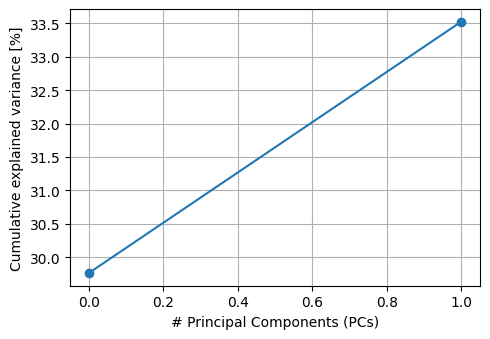

33.52818780123718
Silhouette score for 3 clusters: 0.7661655528411115
Silhouette score for 5 clusters: 0.6775672409226594
Silhouette score for 7 clusters: 0.6532134836858736
Silhouette score for 9 clusters: 0.613482308106072


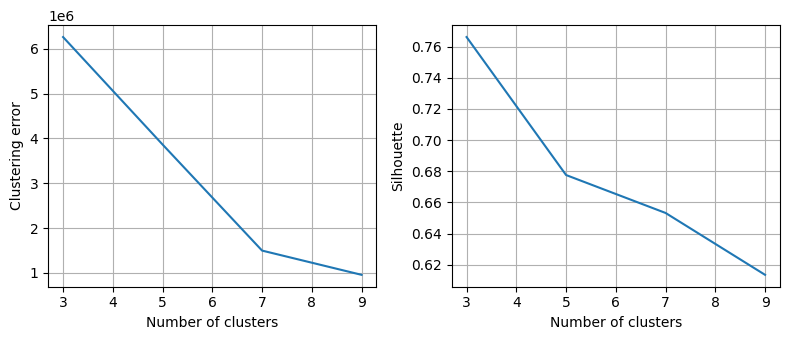

In [27]:
PCA_number_components=2

pca=PCA(n_components=PCA_number_components)
pca.fit(vectorizedData)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
#plt.xticks([i for i in range(0,PCA_number_components,PCA_number_components//10)], [i for i in range(1,PCA_number_components+1,PCA_number_components//10)])
plt.grid()
#plt.title(f'{(PCA_number_components/2)} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)-1], 2)}% of'+r'$\sigma^2$')
plt.tight_layout()
plt.show()
print(perc_cumul_exp_var[-1])
pca_result = pca.transform(vectorizedData)
kmeans_results = []
silhouetteScores=[]

for n_clusters in number_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(pca_result)
    kmeans_results.append(kmeans)
    try:
        silhouetteScores.append(silhouette_score(pca_result, kmeans.labels_, sample_size=n_sample))
        print(f"Silhouette score for {n_clusters} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in number_of_clusters], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in number_of_clusters], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
#plt.title("KMeans clustering results using Bag Of Words")
plt.tight_layout()
plt.show()